# HF-Net 风格：多相机独立建图 + 独立 Query

**Kernel:** `pixel-racers`  
**论文:** [arXiv:1812.03506](https://arxiv.org/abs/1812.03506)

对 **`r` / `fr` / `rl` 各自**跑完整链路（地图与检索库互不共享）：

1. Lap2：特征 → ±2 NN 匹配 → GT 极线三角化 → 全局描述库  
2. Lap3：同相机 query → top-5 → NN → PnP  

**`fr` 特殊处理**：用 `fr-auto-mask/polygons.json` 屏蔽赛车本体（引擎盖/右前轮等），特征只在 `mask==255` 区域提取。

默认后端 `sp_nv_nn`（SP+NetVLAD+NN）；有 `models/hfnet.onnx` 时可改 `hfnet_onnx`。

## 评测指标（与 camloc / cut_120m `evaluate.py` 对齐）

| 指标 | 含义 |
|---|---|
| **Option A** Position RMSE | map 系 √mean(dx²+dy²) |
| **Option B** S/N RMSE | 赛道坐标系（`map.mcap` racing line），见 `23-00-38_cut_120m_update/tools` |
| Yaw RMSE | Option A，度 |
| Poses within 1.0 m | 成功位姿中 err&lt;1 m 的比例 |
| Runtime / frame | 单帧 localize 耗时 |

**§4**：按 `SFM_FEASIBILITY.md` §10.5 对 `r/fr/rl` 做位姿融合并对比指标。


In [2]:
from __future__ import annotations

import importlib
import json
import os
import sys
import time
from pathlib import Path

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name == "3d-map-test":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "3d-map-test"))

import sfm_experiment as sfm
import sfm_hfnet as hf

sfm = importlib.reload(sfm)
hf = importlib.reload(hf)

OUT = ROOT / "3d-map-test" / "outputs_hfnet"
OUT.mkdir(parents=True, exist_ok=True)
POLYGONS = ROOT / "fr-auto-mask" / "polygons.json"
MAP_MCAP = ROOT.parent / "c0_2026-10-13_22-53-42_camloc" / "23-00-38_cut_120m_update" / "map.mcap"

# ---- 多相机：各自独立 map / query ----
CAMERAS = ["r", "fr", "rl"]

BACKEND = "sp_nv_nn"          # 或 "hfnet_onnx"
MAP_LAP, QUERY_LAP = 2, 3
MAP_MAX_FRAMES = None
QUERY_MAX_FRAMES = None
MAP_STRIDE = 1
QUERY_STRIDE = 1
SP_RESIZE = 512
SP_MAX_KP = 1024
MIN_NN_DIST = 0.50
MATCH_WINDOW = 2
TOP_K = 5
EPI_THRESH_PX = 6.0
NN_RATIO = 0.8
OVERRIDE_MAP = False

print("ROOT", ROOT)
print("CAMERAS", CAMERAS)
print("BACKEND", BACKEND, "| OUT", OUT)
print("polygons", POLYGONS, "exists", POLYGONS.is_file())
print("map.mcap (option B)", MAP_MCAP, "exists", MAP_MCAP.is_file())
print("device", sfm.pick_device())


/Users/hbai/SchubKI/PixelRacers/pixel-racers/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


ROOT /Users/hbai/SchubKI/PixelRacers
CAMERAS ['r', 'fr', 'rl']
BACKEND sp_nv_nn | OUT /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs_hfnet
polygons /Users/hbai/SchubKI/PixelRacers/fr-auto-mask/polygons.json exists True
map.mcap (option B) /Users/hbai/SchubKI/c0_2026-10-13_22-53-42_camloc/23-00-38_cut_120m_update/map.mcap exists True
device mps


## 1. 圈次 + 特征器 + `fr` 遮罩预览


laps 2 167.594185587 s / 3 123.628026554 s
  r: t_base=[-2.28 -0.    0.07]
  fr: t_base=[ 0.94646774 -0.16        0.344     ]
  rl: t_base=[0.15146774 0.12       0.42      ]
features SPNVJointFeatures


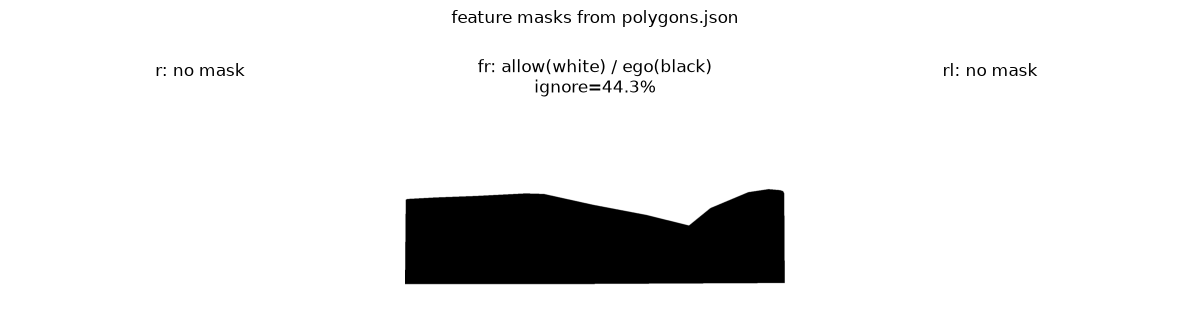

In [3]:
gt = sfm.load_gt()
lap_map = sfm.load_lap(MAP_LAP)
lap_q = sfm.load_lap(QUERY_LAP)
print("laps", MAP_LAP, lap_map["duration_s"], "s /", QUERY_LAP, lap_q["duration_s"], "s")

calibs = {c: sfm.load_camera_calib(c) for c in CAMERAS}
for c, cal in calibs.items():
    print(f"  {c}: t_base={cal.T_base_cam[:3, 3]}")

if BACKEND == "hfnet_onnx":
    feats = hf.make_features(
        "hfnet_onnx",
        onnx_path=hf.DEFAULT_ONNX,
        max_keypoints=SP_MAX_KP,
        resize=SP_RESIZE,
        ratio=NN_RATIO,
    )
else:
    feats = hf.make_features(
        "sp_nv_nn",
        max_keypoints=SP_MAX_KP,
        resize=SP_RESIZE,
        ratio=NN_RATIO,
    )
print("features", type(feats).__name__)

# 预览各相机 ego mask（fr 应有大块车体）
fig, axes = plt.subplots(1, len(CAMERAS), figsize=(4 * len(CAMERAS), 3))
if len(CAMERAS) == 1:
    axes = [axes]
for ax, cam in zip(axes, CAMERAS):
    m = hf.load_ego_mask(cam, POLYGONS)
    if m is None:
        ax.set_title(f"{cam}: no mask")
        ax.axis("off")
        continue
    ax.imshow(m, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{cam}: allow(white) / ego(black)\nignore={(m==0).mean()*100:.1f}%")
    ax.axis("off")
fig.suptitle("feature masks from polygons.json", y=1.02)
fig.tight_layout()
plt.show()


## 2. 逐相机：Lap2 建图 + Lap3 Query

每个相机写入 `outputs_hfnet/map_{cam}/` 与 `outputs_hfnet/loc_lap3_{cam}/`。  
`fr` 在特征提取前/后应用 ego 遮罩；`r`/`rl` 无多边形则全图。


In [4]:
from tqdm.auto import tqdm

runs = {}
for cam in CAMERAS:
    print("\n" + "=" * 60)
    print("CAMERA", cam)
    print("=" * 60)
    runs[cam] = hf.run_camera_pipeline(
        cam,
        feats=feats,
        calib=calibs[cam],
        gt=gt,
        lap_map=lap_map,
        lap_q=lap_q,
        out_root=OUT,
        map_max_frames=MAP_MAX_FRAMES,
        query_max_frames=QUERY_MAX_FRAMES,
        map_stride=MAP_STRIDE,
        query_stride=QUERY_STRIDE,
        min_nn_dist=MIN_NN_DIST,
        match_window=MATCH_WINDOW,
        epi_thresh_px=EPI_THRESH_PX,
        top_k=TOP_K,
        override_map=OVERRIDE_MAP,
        polygons_path=POLYGONS,
    )
print("\ndone cameras:", list(runs))



CAMERA r
[r] no ego polygons — full frame features
[r] LOAD map /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs_hfnet/map_r/map_bundle.npz


load camera_r:   0%|          | 0/1236 [00:00<?, ?frm/s]

[r] query extract 1235 in 14.8s


feat-qry-r:   0%|          | 0/1235 [00:00<?, ?frm/s]

[r] query features 260.7s


...

[rl] query extract 1236 in 14.9s


feat-qry-rl:   0%|          | 0/1236 [00:00<?, ?frm/s]

[rl] query features 316.2s


loc-rl:   0%|          | 0/1236 [00:00<?, ?qry/s]

[rl 0] ok=True corr=252 inl=47 err=19.834316541502687
[rl 1] ok=True corr=255 inl=51 err=20.013672161628634
[rl 2] ok=True corr=294 inl=52 err=19.885779934117586
[rl 3] ok=True corr=293 inl=111 err=19.89022846901207
[rl 4] ok=True corr=323 inl=97 err=19.878507526491354
[rl 5] ok=True corr=301 inl=98 err=19.793107756509034
[rl 6] ok=True corr=292 inl=53 err=40.00047414228654
[rl 7] ok=True corr=245 inl=53 err=39.819996723860584
[rl 8] ok=True corr=232 inl=64 err=40.13031319871919
[rl 9] ok=True corr=199 inl=49 err=39.68416608161567
[rl 49] ok=True corr=478 inl=146 err=0.15909293108939004
[rl 99] ok=True corr=204 inl=99 err=0.10497296473406231
[rl 149] ok=False corr=57 inl=0 err=None
[rl 199] ok=False corr=21 inl=0 err=None
[rl 249] ok=True corr=124 inl=65 err=0.24405541064269723
[rl 299] ok=True corr=41 inl=15 err=0.9674570347522461
[rl 349] ok=False corr=23 inl=0 err=None
[rl 399] ok=False corr=18 inl=0 err=None
[rl 449] ok=True corr=41 inl=22 err=0.1947663996272399
[rl 499] ok=True co

## 3. 官方风格 Metrics（每相机）+ 轨迹图

对齐 `c0_.../23-00-38_cut_120m_update/tools/evaluate.py`：

- **Option A**：map `x,y` Position RMSE、Yaw RMSE、within 1.0 m  
- **Option B**：racing line `(s,n)` RMSE（需 `map.mcap`）  
- **Runtime / frame**：PnP 定位段计时  

可在无重跑建图时单独执行本 cell（需内存中仍有 `runs`，或已写入的 `errors.csv` 含 pred）。



========== camera_r ==========
success              522/1235  (42.3%)
[A] position RMSE    7.103 m   <- SCORE
[A] lateral / lon    1.914 / 6.841 m
[A] yaw RMSE         0.883 deg
[A] within 1.0 m     54.4 % (of success)  |  23.0 % (of all)
[B] pos RMSE (s,n)   7.071 m
[B] s / n RMSE       6.791 / 1.969 m
runtime / frame      16.5 ms mean  (med 18.8, p95 25.9)
wrote /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs_hfnet/loc_lap3_r/submission_xy.csv


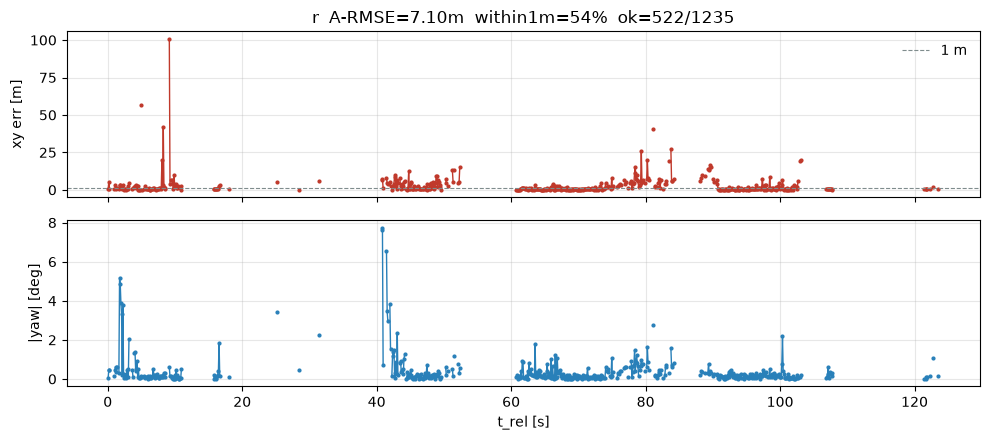

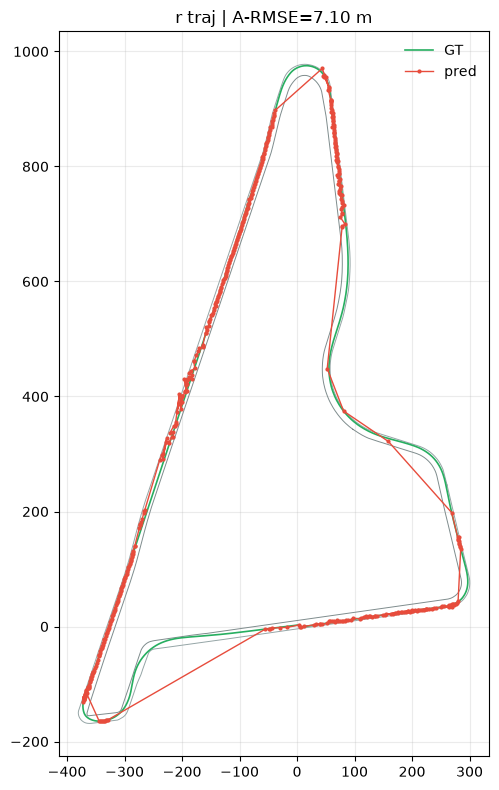


========== camera_fr ==========
success              901/1236  (72.9%)
[A] position RMSE    7.651 m   <- SCORE
[A] lateral / lon    2.758 / 7.137 m
[A] yaw RMSE         1.273 deg
[A] within 1.0 m     51.6 % (of success)  |  37.6 % (of all)
[B] pos RMSE (s,n)   7.646 m
[B] s / n RMSE       7.095 / 2.850 m
runtime / frame      42.6 ms mean  (med 42.2, p95 65.2)
wrote /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs_hfnet/loc_lap3_fr/submission_xy.csv


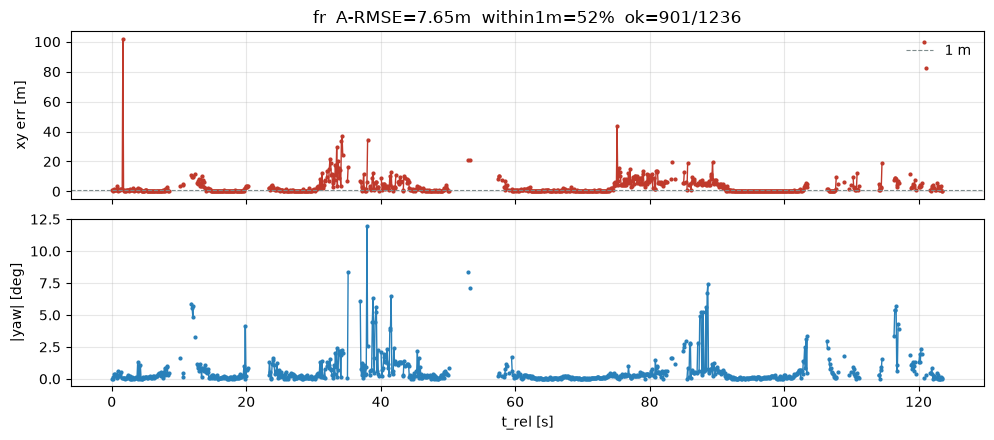

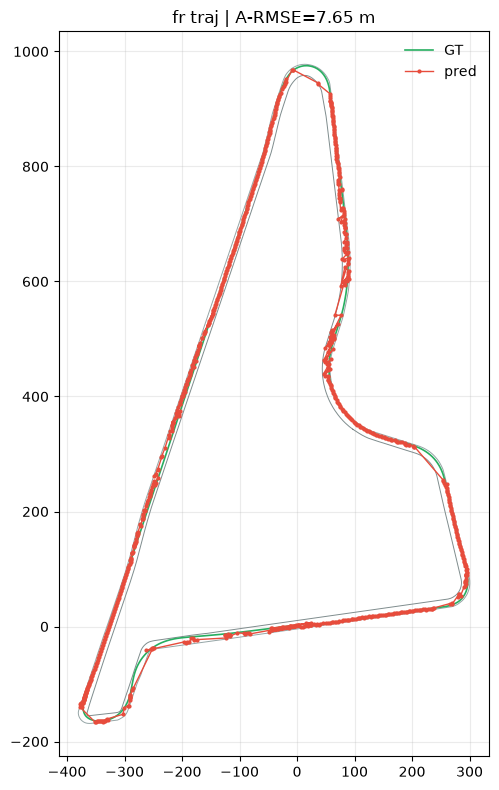


========== camera_rl ==========
success              701/1236  (56.7%)
[A] position RMSE    18.589 m   <- SCORE
[A] lateral / lon    1.890 / 18.492 m
[A] yaw RMSE         0.871 deg
[A] within 1.0 m     73.2 % (of success)  |  41.5 % (of all)
[B] pos RMSE (s,n)   18.585 m
[B] s / n RMSE       18.479 / 1.981 m
runtime / frame      41.6 ms mean  (med 42.3, p95 55.0)
wrote /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs_hfnet/loc_lap3_rl/submission_xy.csv


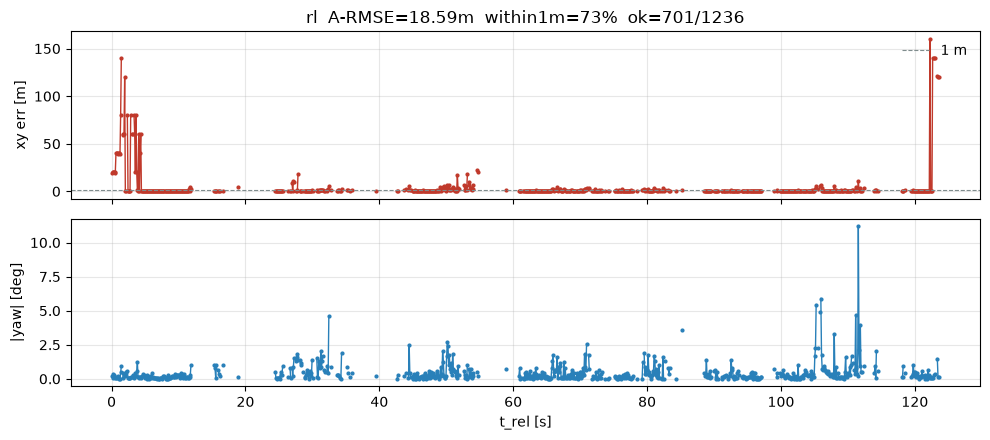

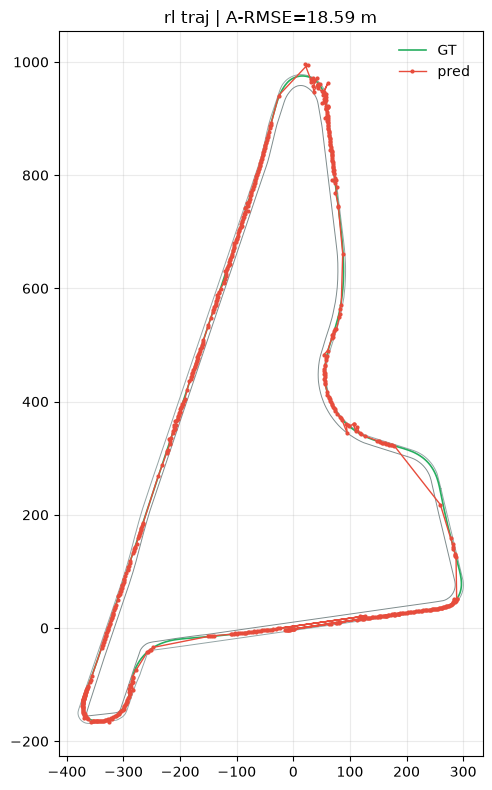


=== metrics table (figure) ===
camera  n_query  n_success  success_rate_%  pos_rmse_xy_m  lat_rmse_m  lon_rmse_m  pos_rmse_sn_m  s_rmse_m  n_rmse_m  yaw_rmse_deg  within_1m_%  within_1m_of_all_%  runtime_ms_mean  runtime_ms_median  runtime_ms_p95
     r     1235        522          42.267          7.103       1.914       6.841          7.071     6.791     1.969         0.883       54.406              22.996           16.508             18.775          25.930
    fr     1236        901          72.896          7.651       2.758       7.137          7.646     7.095     2.850         1.273       51.609              37.621           42.616             42.158          65.190
    rl     1236        701          56.715         18.589       1.890      18.492         18.585    18.479     1.981         0.871       73.181              41.505           41.575             42.312          54.962
wrote /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs_hfnet/metrics_official.csv
saved /Users/hbai/S

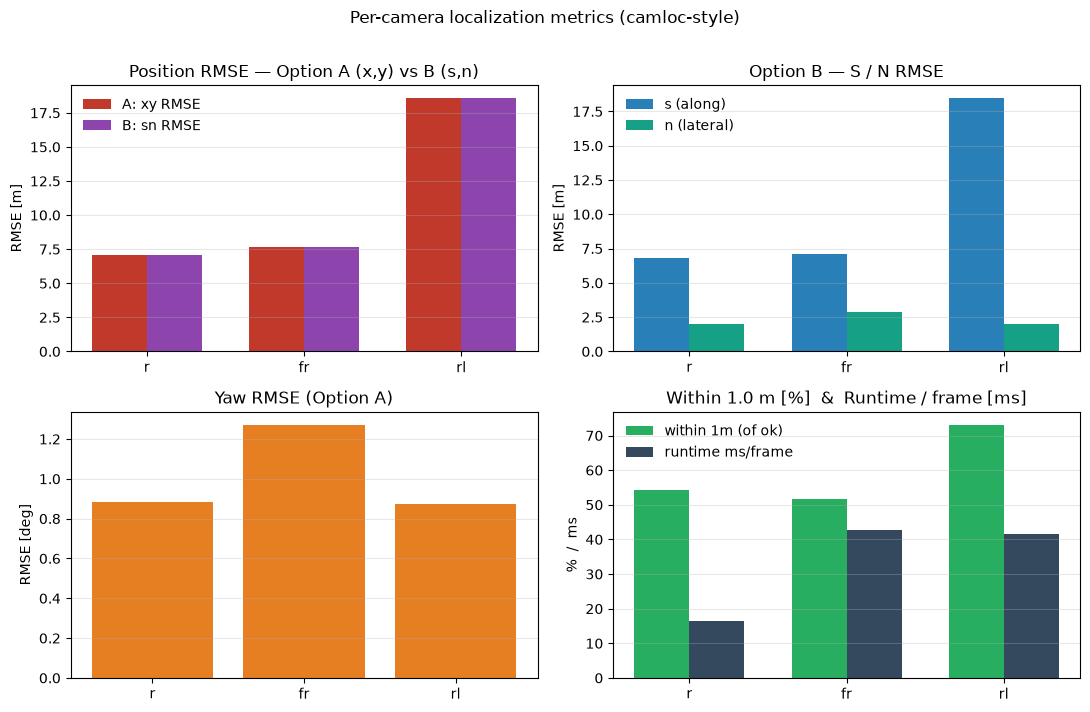

In [5]:
import importlib
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "3d-map-test":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "3d-map-test"))

import sfm_experiment as sfm
import sfm_hfnet as hf

sfm = importlib.reload(sfm)
hf = importlib.reload(hf)

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MAP_MCAP = globals().get(
    "MAP_MCAP",
    ROOT.parent / "c0_2026-10-13_22-53-42_camloc" / "23-00-38_cut_120m_update" / "map.mcap",
)
if "lap_q" not in dir():
    lap_q = sfm.load_lap(globals().get("QUERY_LAP", 3))
if "OUT" not in dir():
    OUT = ROOT / "3d-map-test" / "outputs_hfnet"
if "POLYGONS" not in dir():
    POLYGONS = ROOT / "fr-auto-mask" / "polygons.json"

with open(sfm.EXTRACTED / "track_bounds.json") as f:
    tb = json.load(f)
tl = np.array([[p["x"], p["y"]] for p in tb["track_left"]["points"]], float)
trb = np.array([[p["x"], p["y"]] for p in tb["track_right"]["points"]], float)

# 若无 runs（例如只重开 kernel），尝试从 disk 拼装
if "runs" not in dir() or not runs:
    runs = {}
    for cam in globals().get("CAMERAS", ["r", "fr", "rl"]):
        loc_dir = OUT / f"loc_lap3_{cam}"
        err_path = loc_dir / "errors.csv"
        if not err_path.is_file():
            print("skip", cam, "— no errors.csv")
            continue
        df = pd.read_csv(err_path)
        has_pred = "pred_x" in df.columns
        has_gt_yaw = "gt_yaw" in df.columns
        if not has_pred:
            print(f"[{cam}] legacy errors.csv（无 pred）— Option A 用 err_xy；Option B 需重跑 §2")

        class _Q:
            pass

        qf, results = [], []
        for row in df.itertuples(index=False):
            q = _Q()
            q.stamp_ns = int(row.stamp_ns)
            gyaw = float(row.gt_yaw) if has_gt_yaw and pd.notna(row.gt_yaw) else 0.0
            q.gt_xyzyaw = (float(row.gt_x), float(row.gt_y), 0.0, gyaw)
            qf.append(q)
            ok_i = bool(row.ok)
            if ok_i and has_pred and pd.notna(row.pred_x):
                pred = (float(row.pred_x), float(row.pred_y), 0.0, float(row.pred_yaw))
            elif ok_i and pd.notna(row.err_xy):
                # 仅有标量误差：沿 +x 放置，供 A 的 RMSE/within1m；B 会不准
                pred = (float(row.gt_x) + float(row.err_xy), float(row.gt_y), 0.0, gyaw)
            else:
                pred = None
            r = {
                "ok": ok_i,
                "pred": pred,
                "err_xy": row.err_xy if pd.notna(row.err_xy) else None,
                "err_yaw_deg": row.err_yaw_deg
                if pd.notna(getattr(row, "err_yaw_deg", np.nan))
                else None,
                "n_pnp_corr": int(row.n_pnp_corr),
                "n_pnp_inl": int(row.n_pnp_inl),
            }
            results.append(r)
        runs[cam] = {
            "camera": cam,
            "loc_dir": loc_dir,
            "map_dir": OUT / f"map_{cam}",
            "query_frames": qf,
            "results": results,
            "points": np.zeros((0, 3)),
            "ego_mask": hf.load_ego_mask(cam, POLYGONS) if "POLYGONS" in dir() else None,
            "localize_times_s": None,
            "legacy_no_pred": not has_pred,
        }
        print("loaded", cam, "from", err_path, "pred" if has_pred else "err_xy-only")

metric_rows = []

for cam, run in runs.items():
    qf, results = run["query_frames"], run["results"]
    loc_dir = Path(run["loc_dir"])
    loc_dir.mkdir(parents=True, exist_ok=True)

    stamps = np.array([q.stamp_ns for q in qf], dtype=np.int64)
    t_rel = (stamps - int(lap_q["start_ns"])) * 1e-9
    gt_xy = np.array([q.gt_xyzyaw[:2] for q in qf], dtype=np.float64)
    gt_yaw = np.array([q.gt_xyzyaw[3] for q in qf], dtype=np.float64)
    pred_xy = np.full((len(results), 2), np.nan)
    pred_yaw = np.full(len(results), np.nan)
    err_xy = np.full(len(results), np.nan)
    err_yaw = np.full(len(results), np.nan)
    ok = np.array([bool(r["ok"]) for r in results])

    rows = []
    for i, (q, r) in enumerate(zip(qf, results)):
        if r["ok"] and r["pred"] is not None:
            pred_xy[i] = r["pred"][:2]
            pred_yaw[i] = r["pred"][3]
            err_xy[i] = r["err_xy"]
            err_yaw[i] = abs(r["err_yaw_deg"]) if r["err_yaw_deg"] is not None else np.nan
        rows.append(
            {
                "idx": i,
                "stamp_ns": int(q.stamp_ns),
                "t_rel_s": float(t_rel[i]),
                "ok": bool(r["ok"]),
                "gt_x": float(q.gt_xyzyaw[0]),
                "gt_y": float(q.gt_xyzyaw[1]),
                "gt_yaw": float(q.gt_xyzyaw[3]),
                "pred_x": None if not r["ok"] else float(r["pred"][0]),
                "pred_y": None if not r["ok"] else float(r["pred"][1]),
                "pred_yaw": None if not r["ok"] else float(r["pred"][3]),
                "err_xy": r["err_xy"],
                "err_yaw_deg": None if r["err_yaw_deg"] is None else abs(r["err_yaw_deg"]),
                "n_pnp_corr": r["n_pnp_corr"],
                "n_pnp_inl": r["n_pnp_inl"],
                "camera": cam,
                "backend": globals().get("BACKEND", ""),
            }
        )
    df = pd.DataFrame(rows)
    df.to_csv(loc_dir / "errors.csv", index=False)

    # submission for official evaluate.py (successful poses only)
    sub = df.loc[df["ok"], ["stamp_ns", "pred_x", "pred_y", "pred_yaw"]].rename(
        columns={"pred_x": "x", "pred_y": "y", "pred_yaw": "yaw"}
    )
    sub_path = loc_dir / "submission_xy.csv"
    sub.to_csv(sub_path, index=False)

    m = hf.compute_camloc_metrics(
        stamps_ns=stamps,
        gt_xy=gt_xy,
        gt_yaw=gt_yaw,
        pred_xy=pred_xy,
        pred_yaw=pred_yaw,
        ok=ok,
        localize_times_s=run.get("localize_times_s"),
        map_mcap=MAP_MCAP,
    )
    if run.get("legacy_no_pred") and ok.any():
        # 旧 csv 无真实 pred：A 的位置/yaw 用 err_*；B 标为不可用
        e = err_xy[ok]
        y = err_yaw[ok]
        m["pos_rmse_xy_m"] = float(np.sqrt(np.nanmean(e**2)))
        m["yaw_rmse_deg"] = float(np.sqrt(np.nanmean(y**2)))
        m["within_1m_%"] = 100.0 * float(np.mean(e < 1.0))
        m["within_1m_of_all_%"] = 100.0 * float(np.sum(e < 1.0) / max(len(ok), 1))
        m["lat_rmse_m"] = m["lon_rmse_m"] = float("nan")
        m["pos_rmse_sn_m"] = m["s_rmse_m"] = m["n_rmse_m"] = float("nan")
        m["legacy_note"] = "no pred_*; Option B unavailable — re-run §2"
    m["camera"] = cam
    metric_rows.append(m)

    print(f"\n========== camera_{cam} ==========")
    print(f"success              {m['n_success']}/{m['n_query']}  ({m['success_rate_%']:.1f}%)")
    print(f"[A] position RMSE    {m['pos_rmse_xy_m']:.3f} m   <- SCORE")
    print(f"[A] lateral / lon    {m['lat_rmse_m']:.3f} / {m['lon_rmse_m']:.3f} m")
    print(f"[A] yaw RMSE         {m['yaw_rmse_deg']:.3f} deg")
    print(f"[A] within 1.0 m     {m['within_1m_%']:.1f} % (of success)  |  {m['within_1m_of_all_%']:.1f} % (of all)")
    print(f"[B] pos RMSE (s,n)   {m['pos_rmse_sn_m']:.3f} m")
    print(f"[B] s / n RMSE       {m['s_rmse_m']:.3f} / {m['n_rmse_m']:.3f} m")
    print(
        f"runtime / frame      {m['runtime_ms_mean']:.1f} ms mean  "
        f"(med {m['runtime_ms_median']:.1f}, p95 {m['runtime_ms_p95']:.1f})"
    )
    print("wrote", sub_path)

    # --- plots: err vs time ---
    fig, axes = plt.subplots(2, 1, figsize=(10, 4.5), sharex=True)
    axes[0].plot(t_rel, err_xy, color="#c0392b", lw=1.0, marker="o", ms=2)
    axes[0].axhline(1.0, color="#7f8c8d", ls="--", lw=0.8, label="1 m")
    axes[0].set_ylabel("xy err [m]")
    axes[0].set_title(
        f"{cam}  A-RMSE={m['pos_rmse_xy_m']:.2f}m  within1m={m['within_1m_%']:.0f}%  "
        f"ok={m['n_success']}/{m['n_query']}"
    )
    axes[0].legend(frameon=False, loc="upper right")
    axes[0].grid(True, alpha=0.3)
    axes[1].plot(t_rel, err_yaw, color="#2980b9", lw=1.0, marker="o", ms=2)
    axes[1].set_ylabel("|yaw| [deg]")
    axes[1].set_xlabel("t_rel [s]")
    axes[1].grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig(loc_dir / "err_vs_time.png", dpi=140)
    plt.show()

    # traj
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.plot(tl[:, 0], tl[:, 1], color="#7f8c8d", lw=0.7)
    ax.plot(trb[:, 0], trb[:, 1], color="#95a5a6", lw=0.7)
    ax.plot(gt_xy[:, 0], gt_xy[:, 1], color="#27ae60", lw=1.2, label="GT")
    if ok.any():
        ax.plot(
            pred_xy[ok, 0], pred_xy[ok, 1],
            color="#e74c3c", lw=1.0, marker="o", ms=2, label="pred",
        )
    ax.set_aspect("equal", adjustable="box")
    ax.legend(frameon=False)
    ax.set_title(f"{cam} traj | A-RMSE={m['pos_rmse_xy_m']:.2f} m")
    ax.grid(True, alpha=0.25)
    fig.tight_layout()
    fig.savefig(loc_dir / "traj_vs_gt.png", dpi=140)
    plt.show()

mdf = pd.DataFrame(metric_rows)
# friendly column order matching the figure
cols = [
    "camera",
    "n_query",
    "n_success",
    "success_rate_%",
    "pos_rmse_xy_m",
    "lat_rmse_m",
    "lon_rmse_m",
    "pos_rmse_sn_m",
    "s_rmse_m",
    "n_rmse_m",
    "yaw_rmse_deg",
    "within_1m_%",
    "within_1m_of_all_%",
    "runtime_ms_mean",
    "runtime_ms_median",
    "runtime_ms_p95",
]
mdf = mdf[[c for c in cols if c in mdf.columns]]
mdf.to_csv(OUT / "metrics_official.csv", index=False)
print("\n=== metrics table (figure) ===")
print(mdf.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
print("wrote", OUT / "metrics_official.csv")

# --- comparison bars ---
cams = mdf["camera"].tolist()
x = np.arange(len(cams))
w = 0.35

fig, axes = plt.subplots(2, 2, figsize=(11, 7))

ax = axes[0, 0]
ax.bar(x - w / 2, mdf["pos_rmse_xy_m"], w, label="A: xy RMSE", color="#c0392b")
ax.bar(x + w / 2, mdf["pos_rmse_sn_m"], w, label="B: sn RMSE", color="#8e44ad")
ax.set_xticks(x)
ax.set_xticklabels(cams)
ax.set_ylabel("RMSE [m]")
ax.set_title("Position RMSE — Option A (x,y) vs B (s,n)")
ax.legend(frameon=False)
ax.grid(True, axis="y", alpha=0.3)

ax = axes[0, 1]
ax.bar(x - w / 2, mdf["s_rmse_m"], w, label="s (along)", color="#2980b9")
ax.bar(x + w / 2, mdf["n_rmse_m"], w, label="n (lateral)", color="#16a085")
ax.set_xticks(x)
ax.set_xticklabels(cams)
ax.set_ylabel("RMSE [m]")
ax.set_title("Option B — S / N RMSE")
ax.legend(frameon=False)
ax.grid(True, axis="y", alpha=0.3)

ax = axes[1, 0]
ax.bar(x, mdf["yaw_rmse_deg"], color="#e67e22")
ax.set_xticks(x)
ax.set_xticklabels(cams)
ax.set_ylabel("RMSE [deg]")
ax.set_title("Yaw RMSE (Option A)")
ax.grid(True, axis="y", alpha=0.3)

ax = axes[1, 1]
ax.bar(x - w / 2, mdf["within_1m_%"], w, label="within 1m (of ok)", color="#27ae60")
ax.bar(x + w / 2, mdf["runtime_ms_mean"], w, label="runtime ms/frame", color="#34495e")
ax.set_xticks(x)
ax.set_xticklabels(cams)
ax.set_ylabel("%  /  ms")
ax.set_title("Within 1.0 m [%]  &  Runtime / frame [ms]")
ax.legend(frameon=False)
ax.grid(True, axis="y", alpha=0.3)

fig.suptitle("Per-camera localization metrics (camloc-style)", y=1.01)
fig.tight_layout()
fig.savefig(OUT / "metrics_compare.png", dpi=150)
print("saved", OUT / "metrics_compare.png")
plt.show()


## 4. 三相机位姿融合（SFM_FEASIBILITY §10.5）

对各相机独立定位结果做 **base_link 位姿层**融合（不融特征）：

\[
\omega = \mathbf{1}[\mathrm{ok}]\cdot n_{\mathrm{inl}}\cdot\exp(-\bar{e}_{\mathrm{reproj}}/\sigma)
\]

当前无重投影误差时退化为 \(\omega=n_{\mathrm{inl}}\)。对比：

1. **hard**：硬选优（最大 \(\omega\)）
2. **se2**：门控 + SE(2) 加权
3. **union oracle**：至少一路成功（上界，非因果融合）


load r: 1235  ok=522 (42.3%)
load fr: 1236  ok=901 (72.9%)
load rl: 1236  ok=701 (56.7%)
fuse[hard] success 1065/1235  union_ok 1065  modes={'hard_select': 1065}
fuse[se2] success 1065/1235  union_ok 1065  modes={'se2_weighted': 540, 'single': 525}

--- complementarity (aligned to r stamps) ---
  P(ok_r) = 42.3%
  P(ok_fr) = 72.9%
  P(ok_rl) = 56.7%
  P(union) = 86.2%
  P(fr|fail_r) = 58.8%
  P(rl|fail_r) = 42.8%

=== single vs fused ===
         camera  n_query  n_success  success_rate_%  pos_rmse_xy_m  lat_rmse_m  lon_rmse_m  pos_rmse_sn_m  s_rmse_m  n_rmse_m  yaw_rmse_deg  within_1m_%  within_1m_of_all_%
              r     1235        522          42.267          7.103       1.914       6.841          7.071     6.791     1.969         0.883       54.406              22.996
             fr     1236        901          72.896          7.651       2.758       7.137          7.646     7.095     2.850         1.273       51.609              37.621
             rl     1236        701    

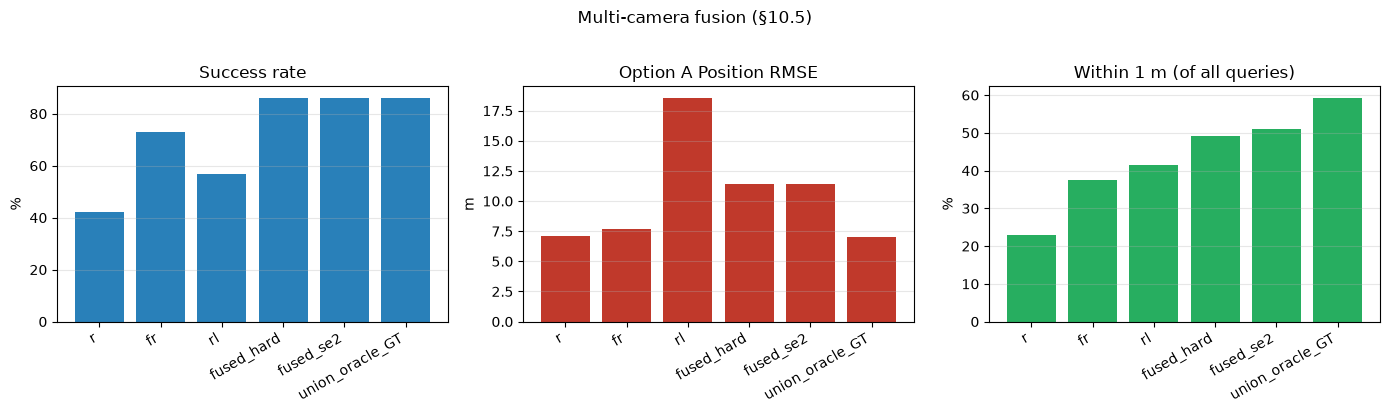

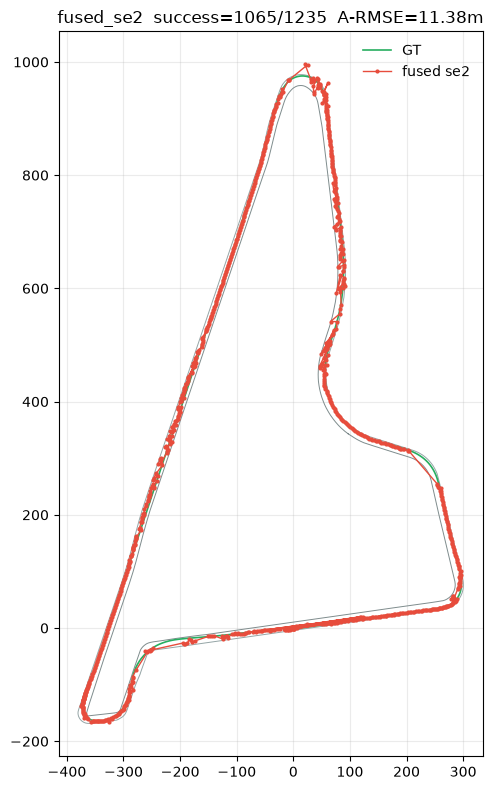

saved /Users/hbai/SchubKI/PixelRacers/3d-map-test/outputs_hfnet/loc_lap3_fused


In [6]:
import importlib
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "3d-map-test":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "3d-map-test"))

import sfm_experiment as sfm
import sfm_hfnet as hf

sfm = importlib.reload(sfm)
hf = importlib.reload(hf)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUT = globals().get("OUT", ROOT / "3d-map-test" / "outputs_hfnet")
MAP_MCAP = globals().get(
    "MAP_MCAP",
    ROOT.parent / "c0_2026-10-13_22-53-42_camloc" / "23-00-38_cut_120m_update" / "map.mcap",
)
CAMERAS = globals().get("CAMERAS", ["r", "fr", "rl"])
if "lap_q" not in dir():
    lap_q = sfm.load_lap(globals().get("QUERY_LAP", 3))

tables = {}
for cam in CAMERAS:
    p = OUT / f"loc_lap3_{cam}" / "errors.csv"
    df = pd.read_csv(p)
    need = {"stamp_ns", "ok", "gt_x", "gt_y", "gt_yaw", "pred_x", "pred_y", "pred_yaw", "n_pnp_inl"}
    miss = need - set(df.columns)
    if miss:
        raise RuntimeError(f"{p} missing {miss} — re-run metrics/loc to write pred_*")
    tables[cam] = df
    print(f"load {cam}: {len(df)}  ok={int(df.ok.sum())} ({100*df.ok.mean():.1f}%)")

fuse_dir = OUT / "loc_lap3_fused"
fuse_dir.mkdir(parents=True, exist_ok=True)

fused = {}
for mode in ("hard", "se2"):
    df_f = hf.fuse_multi_camera_tables(
        tables, ref_camera="r", mode=mode, gate_xy_m=5.0, gate_yaw_deg=15.0
    )
    df_f["t_rel_s"] = (df_f["stamp_ns"] - int(lap_q["start_ns"])) * 1e-9
    df_f.to_csv(fuse_dir / f"errors_{mode}.csv", index=False)
    fused[mode] = df_f
    print(f"fuse[{mode}] success {df_f.ok.sum()}/{len(df_f)}  "
          f"union_ok {df_f.union_ok.sum()}  modes={df_f.fuse_mode.value_counts().to_dict()}")

# complementarity on aligned table (from se2 align)
df_a = fused["se2"]
ok_cols = [c for c in df_a.columns if c.startswith("ok_") and c != "ok"]
print("\n--- complementarity (aligned to r stamps) ---")
for c in ok_cols:
    print(f"  P({c}) = {100*df_a[c].mean():.1f}%")
print(f"  P(union) = {100*df_a.union_ok.mean():.1f}%")
print(f"  P(fr|fail_r) = {100*df_a.loc[~df_a.ok_r, 'ok_fr'].mean():.1f}%" if "ok_fr" in df_a and (~df_a.ok_r).any() else "")
print(f"  P(rl|fail_r) = {100*df_a.loc[~df_a.ok_r, 'ok_rl'].mean():.1f}%" if "ok_rl" in df_a and (~df_a.ok_r).any() else "")

# metrics: singles + fused + union oracle
metric_rows = []

def metrics_from_df(df, name, times=None):
    ok = df["ok"].astype(bool).to_numpy()
    pred_xy = np.c_[df["pred_x"].to_numpy(float), df["pred_y"].to_numpy(float)]
    pred_yaw = df["pred_yaw"].to_numpy(float)
    gt_xy = np.c_[df["gt_x"].to_numpy(float), df["gt_y"].to_numpy(float)]
    gt_yaw = df["gt_yaw"].to_numpy(float)
    m = hf.compute_camloc_metrics(
        stamps_ns=df["stamp_ns"].to_numpy(),
        gt_xy=gt_xy,
        gt_yaw=gt_yaw,
        pred_xy=pred_xy,
        pred_yaw=pred_yaw,
        ok=ok,
        localize_times_s=times,
        map_mcap=MAP_MCAP,
    )
    m["camera"] = name
    return m

for cam, df in tables.items():
    metric_rows.append(metrics_from_df(df, cam))

for mode, df_f in fused.items():
    metric_rows.append(metrics_from_df(df_f, f"fused_{mode}"))

# union oracle: pick among successful the one with min err_xy (uses GT — upper bound only)
ref = tables["r"].sort_values("stamp_ns").reset_index(drop=True)
oracle_rows = []
aligned = {"r": ref}
for c in CAMERAS:
    if c == "r":
        continue
    df = tables[c].sort_values("stamp_ns").reset_index(drop=True)
    ji = hf.align_by_nearest_stamp(ref["stamp_ns"].to_numpy(), df["stamp_ns"].to_numpy())
    aligned[c] = df.iloc[ji].reset_index(drop=True)

for i in range(len(ref)):
    cands = []
    for c in CAMERAS:
        row = aligned[c].iloc[i]
        if bool(row.ok) and pd.notna(row.pred_x):
            cands.append((float(row.err_xy), float(row.pred_x), float(row.pred_y), float(row.pred_yaw)))
    gx, gy, gyaw = float(ref.iloc[i].gt_x), float(ref.iloc[i].gt_y), float(ref.iloc[i].gt_yaw)
    if cands:
        cands.sort()
        _, px, py, pyaw = cands[0]
        err = float(np.hypot(px - gx, py - gy))
        ey = abs(((pyaw - gyaw + np.pi) % (2 * np.pi)) - np.pi) * 180 / np.pi
        oracle_rows.append(dict(stamp_ns=int(ref.iloc[i].stamp_ns), ok=True, gt_x=gx, gt_y=gy, gt_yaw=gyaw,
                                pred_x=px, pred_y=py, pred_yaw=pyaw, err_xy=err, err_yaw_deg=ey))
    else:
        oracle_rows.append(dict(stamp_ns=int(ref.iloc[i].stamp_ns), ok=False, gt_x=gx, gt_y=gy, gt_yaw=gyaw,
                                pred_x=np.nan, pred_y=np.nan, pred_yaw=np.nan, err_xy=np.nan, err_yaw_deg=np.nan))
df_or = pd.DataFrame(oracle_rows)
df_or.to_csv(fuse_dir / "errors_union_oracle.csv", index=False)
metric_rows.append(metrics_from_df(df_or, "union_oracle_GT"))

mdf = pd.DataFrame(metric_rows)
cols = [
    "camera", "n_query", "n_success", "success_rate_%",
    "pos_rmse_xy_m", "lat_rmse_m", "lon_rmse_m",
    "pos_rmse_sn_m", "s_rmse_m", "n_rmse_m",
    "yaw_rmse_deg", "within_1m_%", "within_1m_of_all_%",
]
mdf = mdf[[c for c in cols if c in mdf.columns]]
mdf.to_csv(fuse_dir / "metrics_fused.csv", index=False)
print("\n=== single vs fused ===")
print(mdf.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
print("wrote", fuse_dir / "metrics_fused.csv")
print("note: union_oracle_GT picks min-err among ok cams (uses GT) — upper bound only")

# plots
names = mdf["camera"].tolist()
x = np.arange(len(names))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].bar(x, mdf["success_rate_%"], color="#2980b9")
axes[0].set_xticks(x); axes[0].set_xticklabels(names, rotation=30, ha="right")
axes[0].set_ylabel("%"); axes[0].set_title("Success rate")
axes[0].grid(True, axis="y", alpha=0.3)

axes[1].bar(x, mdf["pos_rmse_xy_m"], color="#c0392b")
axes[1].set_xticks(x); axes[1].set_xticklabels(names, rotation=30, ha="right")
axes[1].set_ylabel("m"); axes[1].set_title("Option A Position RMSE")
axes[1].grid(True, axis="y", alpha=0.3)

axes[2].bar(x, mdf["within_1m_of_all_%"], color="#27ae60")
axes[2].set_xticks(x); axes[2].set_xticklabels(names, rotation=30, ha="right")
axes[2].set_ylabel("%"); axes[2].set_title("Within 1 m (of all queries)")
axes[2].grid(True, axis="y", alpha=0.3)
fig.suptitle("Multi-camera fusion (§10.5)", y=1.02)
fig.tight_layout()
fig.savefig(fuse_dir / "metrics_fuse_compare.png", dpi=150)
plt.show()

# traj fused se2
with open(sfm.EXTRACTED / "track_bounds.json") as f:
    import json as _json
    tb = _json.load(f)
tl = np.array([[p["x"], p["y"]] for p in tb["track_left"]["points"]], float)
trb = np.array([[p["x"], p["y"]] for p in tb["track_right"]["points"]], float)
df_f = fused["se2"]
ok = df_f.ok.to_numpy()
fig, ax = plt.subplots(figsize=(8, 8))
ax.plot(tl[:, 0], tl[:, 1], color="#7f8c8d", lw=0.7)
ax.plot(trb[:, 0], trb[:, 1], color="#95a5a6", lw=0.7)
ax.plot(df_f.gt_x, df_f.gt_y, color="#27ae60", lw=1.2, label="GT")
if ok.any():
    ax.plot(df_f.loc[ok, "pred_x"], df_f.loc[ok, "pred_y"], color="#e74c3c", lw=1.0, marker="o", ms=2, label="fused se2")
ax.set_aspect("equal", adjustable="box")
ax.legend(frameon=False)
ax.set_title(f"fused_se2  success={ok.sum()}/{len(ok)}  A-RMSE={mdf.loc[mdf.camera=='fused_se2','pos_rmse_xy_m'].iloc[0]:.2f}m")
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(fuse_dir / "traj_fused_se2.png", dpi=140)
plt.show()
print("saved", fuse_dir)


## 调参

| 参数 | 说明 |
|---|---|
| `CAMERAS` | 默认 `r, fr, rl`；可增减 |
| `POLYGONS` | `fr-auto-mask/polygons.json`（`fr` 屏蔽车体） |
| `OVERRIDE_MAP` | `True` 强制重建各相机地图 |
| `MAP_STRIDE` / `QUERY_STRIDE` | 默认 2；全圈对比改 1 |
| `BACKEND` | `sp_nv_nn` 或 `hfnet_onnx` |

遮罩约定：`255`=允许提特征，`0`=忽略（车体多边形填充为 0）。

| `MAP_MCAP` | Option B 赛道线（`23-00-38_cut_120m_update/map.mcap`） |
| `metrics_official.csv` | 每相机 A/B/yaw/within1m/runtime |

Option B 生成方式与 `tools/convert.py xy2sn` + `evaluate.py` 一致（本 notebook 内嵌 `track_frame` 投影）。

| §4 融合 | `hard` / `se2` → `outputs_hfnet/loc_lap3_fused/` |
